# Tema 27 · Detectar y segmentar: dónde está cada cosa

Pasar de «qué hay en la imagen» a «dónde está», hasta el nivel de cada píxel, también en video.

Este cuaderno es el tema 27 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/27-detectar-y-segmentar-donde-esta-cada-cosa/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

Primero, las bibliotecas que este tema necesita y que Colab no trae (o trae en otra versión):

In [ ]:
!pip install -q accelerate==1.15.0 transformers==5.21.0

# Teoría

## La pregunta

Una cámara mira una avenida. Un clasificador como los del tema «Redes convolucionales» te diría «en esta foto hay autos». Pero la municipalidad quiere saber **cuántos** autos pasan por minuto, un auto que se maneja solo necesita saber **dónde** está el peatón que cruza, y un programa que borra el fondo de una foto necesita saber **qué píxeles** son de la persona y cuáles no.

Las tres preguntas piden lo mismo: pasar de «qué hay en la imagen» a «dónde está cada cosa». En este tema vas a:

- describir dónde está un objeto con una **caja delimitadora** y medir cuánto se parecen dos cajas con el **IoU**;
- usar tres **detectores** preentrenados (dos clásicos, uno de una etapa y otro de dos, y uno basado en transformers) y comparar qué ven y cuánto tardan;
- programar desde cero la **supresión de no máximos** (NMS), que limpia las cajas repetidas;
- contar vehículos en los cuadros de un **video**;
- entrenar una **U-Net** pequeña que pinta cada píxel con su clase (**segmentación**) y medirla con IoU y Dice.

Necesitas lo del tema «Redes convolucionales» (convoluciones, pooling, `nn.Conv2d`) y, para entender DETR, la atención del tema «Atención y transformers».

## Actividad: cajas que compiten

Un detector no da una caja por objeto: da decenas de cajas candidatas, muchas encimadas sobre el mismo auto, cada una con un **puntaje** de confianza entre 0 y 1. Las 12 cajas de la foto son candidatas reales que dio un detector (Faster R-CNN, que vas a usar más abajo) antes de limpiarlas.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/27-detectar-y-segmentar-donde-esta-cada-cosa/teoria/). Ábrela en el navegador para usarla.
Prueba esto:

1. Toca una caja y después otra encimada. Mira el **IoU**: el área donde se cruzan dividida por el área que cubren entre las dos. Arrastra una de ellas (o muévela con las flechas) y mira cómo cambia: ¿cuánto vale si una está dentro de la otra? ¿Y si no se tocan?
2. Sube el **umbral de confianza**. ¿Qué cajas se apagan primero?
3. Pulsa «Aplicar NMS» varias veces y lee qué pasa en cada paso. ¿Cuántas cajas quedan? ¿Coincide con el número de objetos?
4. Reinicia, baja el **umbral de IoU** a 0,2 y aplica NMS de nuevo. Luego súbelo a 0,8. ¿En cuál de los dos casos sobran cajas repetidas? ¿En cuál se pierden objetos?
5. Mira la caja del peatón. ¿Qué clase le puso el detector?

La NMS es una regla simple: quedarse con la caja de mayor puntaje y borrar las que se le parecen demasiado; repetir con las que sobran. Ese «demasiado» se mide con el IoU y lo decides tú con el umbral. Y el detector se equivoca: al peatón lo llamó «bicicleta». Un detector es un modelo como cualquier otro, con errores que hay que revisar.

## Clasificar, detectar y segmentar

Hay cuatro niveles de «dónde»:

- **Clasificación**: ¿qué hay en la imagen? Da una clase para toda la imagen.
- **Detección**: ¿qué hay y dónde? Da una caja, una clase y un puntaje por cada objeto.
- **Segmentación semántica**: ¿de qué clase es cada píxel? Da una máscara del tamaño de la imagen.
- **Segmentación de instancias**: ¿a qué objeto pertenece cada píxel? Da una máscara por objeto.

La segmentación semántica pinta de un mismo color todos los autos; la de instancias separa el auto 1 del auto 2. Este tema programa las tres primeras; la de instancias aparece al final, en palabras.

Primero, las fotos. Usaremos una foto de una avenida de São Paulo y un video corto de tráfico, los dos de Wikimedia Commons. Son de otras ciudades porque tienen licencia libre; en el mini-proyecto vas a probar con una calle de la tuya. El código los baja una sola vez a la carpeta `datos` (Wikimedia pide que cada programa se identifique con un `User-Agent`).

In [ ]:
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

COMMONS = "https://upload.wikimedia.org/wikipedia/commons/"
CALLE = "Avenida_Faria_Lima%2C_cruce_de_peatones.jpg"
VIDEO = ("Congested_traffic_on_the_Dan_Ryan_Expy_"
         "%2810x_timelapse%29_-_April_2026.webm")


def bajar(nombre, url):
    """Baja un archivo a «datos» si todavía no está y devuelve su ruta."""
    ruta = Path("datos") / nombre
    if not ruta.exists():
        ruta.parent.mkdir(parents=True, exist_ok=True)
        pedido = urllib.request.Request(
            url, headers={"User-Agent": "ruta-obia/1.0 (iabolivia.org)"})
        with urllib.request.urlopen(pedido) as respuesta:
            ruta.write_bytes(respuesta.read())
    return ruta


ruta_calle = bajar("imagenes-ruta/t27-calle.jpg",
                   f"{COMMONS}thumb/9/97/{CALLE}/960px-{CALLE}")
ruta_video = bajar("video-trafico/dan-ryan-480p.webm",
                   f"{COMMONS}transcoded/6/67/{VIDEO}/{VIDEO}.480p.vp9.webm")

foto = Image.open(ruta_calle).convert("RGB")
print("Tamaño de la foto (ancho, alto):", foto.size)

Tamaño de la foto (ancho, alto): (960, 916)


La foto es «Avenida Faria Lima, cruce de peatones», de Wilfredor, cedida al dominio público (CC0) en [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Avenida_Faria_Lima,_cruce_de_peatones.jpg).

## Cajas: dos formas de escribirlas

Una **caja delimitadora** es el rectángulo más chico, con lados horizontales y verticales, que encierra al objeto. Se describe con cuatro números, en píxeles, contando desde la esquina **superior** izquierda de la imagen (el eje *y* crece hacia abajo, como las filas de una matriz). Hay dos formatos comunes:

- **xyxy**: la esquina superior izquierda (*x*₁, *y*₁) y la inferior derecha (*x*₂, *y*₂). Lo usan `torchvision` y DETR al final.
- **xywh**: la esquina superior izquierda, el ancho y el alto. Lo usa el formato de anotaciones COCO.

Algunos modelos usan además el **centro**, el ancho y el alto (cxcywh), a veces divididos por el tamaño de la imagen para que queden entre 0 y 1. Mezclar formatos es el error más común al trabajar con cajas: el código no falla, pero las cajas quedan en cualquier lado.

In [ ]:
def xyxy_a_xywh(c):
    x1, y1, x2, y2 = c
    return np.array([x1, y1, x2 - x1, y2 - y1])


def xywh_a_xyxy(c):
    x, y, w, h = c
    return np.array([x, y, x + w, y + h])


# Una caja alrededor del auto plateado de la izquierda
caja = np.array([251, 536, 348, 629])
print("xyxy:", caja)
print("xywh:", xyxy_a_xywh(caja))
print("y de vuelta:", xywh_a_xyxy(xyxy_a_xywh(caja)))

xyxy: [251 536 348 629]
xywh: [251 536  97  93]
y de vuelta: [251 536 348 629]


## IoU: cuánto se parecen dos cajas

¿Cómo sabemos si una caja predicha «acertó»? Casi nunca coincide al píxel con la caja correcta. Se mide cuánto se superponen con la **intersección sobre la unión** (IoU, por *intersection over union*):

$$\mathrm{IoU} ( A , B ) = \frac{\text{área de } ( A \cap B )}{\text{área de } ( A \cup B )} = \frac{\text{intersección}}{\text{área de } A + \text{área de } B - \text{intersección}}$$

Vale 1 si las cajas son idénticas y 0 si no se tocan. La intersección de dos cajas también es una caja: su borde izquierdo es el mayor de los dos bordes izquierdos, su borde derecho el menor de los dos derechos, y lo mismo arriba y abajo. Si el borde izquierdo queda a la derecha del derecho, no se tocan y el área es 0. La unión se resta la intersección para no contarla dos veces.

In [ ]:
def area(c):
    # Si la caja está «al revés» (no hay intersección), el área es 0
    return max(0, c[2] - c[0]) * max(0, c[3] - c[1])


def iou(a, b):
    """IoU de dos cajas en formato xyxy."""
    interseccion = area([max(a[0], b[0]), max(a[1], b[1]),
                         min(a[2], b[2]), min(a[3], b[3])])
    union = area(a) + area(b) - interseccion
    return interseccion / union


a = [0, 0, 10, 10]
b = [5, 0, 15, 10]     # la misma caja corrida 5 a la derecha
c = [20, 20, 30, 30]   # lejos de las dos
print(f"IoU(a, a) = {iou(a, a):.3f}")
print(f"IoU(a, b) = {iou(a, b):.3f}")
print(f"IoU(a, c) = {iou(a, c):.3f}")

IoU(a, a) = 1.000
IoU(a, b) = 0.333
IoU(a, c) = 0.000


Correr la caja la mitad de su ancho ya baja el IoU a un tercio: se cruzan en 50 píxeles cuadrados, pero entre las dos cubren 150. El IoU es exigente.

Un detector produce cientos de cajas, así que conviene calcular el IoU de **todas contra todas** de una vez, sin bucles. Con el *broadcasting* de NumPy (tema 3), `A[:, None, 0]` tiene forma (*n*, 1) y `B[None, :, 0]` forma (1, *m*) (`None` como índice hace lo mismo que `np.newaxis`: agrega un eje de tamaño 1): al combinarlas sale una tabla de *n* × *m*. Comparamos con `box_iou` de `torchvision.ops`, que hace lo mismo:

In [ ]:
from torchvision.ops import box_iou


def iou_matriz(A, B):
    """IoU de cada caja de A (n x 4) con cada caja de B (m x 4)."""
    x1 = np.maximum(A[:, None, 0], B[None, :, 0])
    y1 = np.maximum(A[:, None, 1], B[None, :, 1])
    x2 = np.minimum(A[:, None, 2], B[None, :, 2])
    y2 = np.minimum(A[:, None, 3], B[None, :, 3])
    interseccion = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (A[:, 2] - A[:, 0]) * (A[:, 3] - A[:, 1])
    area_b = (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1])
    return interseccion / (area_a[:, None] + area_b[None, :] - interseccion)


cajas = np.array([a, b, c], dtype=float)
print(np.round(iou_matriz(cajas, cajas), 3))
print("¿Igual que torchvision?", np.allclose(
    iou_matriz(cajas, cajas), box_iou(torch.tensor(cajas),
                                      torch.tensor(cajas)).numpy()))

[[1.    0.333 0.   ]
 [0.333 1.    0.   ]
 [0.    0.    1.   ]]
¿Igual que torchvision? True


Para tener una idea visual de cuánto es «0,5» o «0,9», dibujemos dos cajas iguales de 10 × 10, la segunda corrida *d* píxeles a la derecha y *d* hacia abajo. Se cruzan en un cuadrado de lado 10 − *d*, así que la intersección es (10 − *d*)² y la unión, 200 − (10 − *d*)². Si queremos un IoU *t*, despejamos: (10 − *d*)² = 200 · *t* / (1 + *t*).

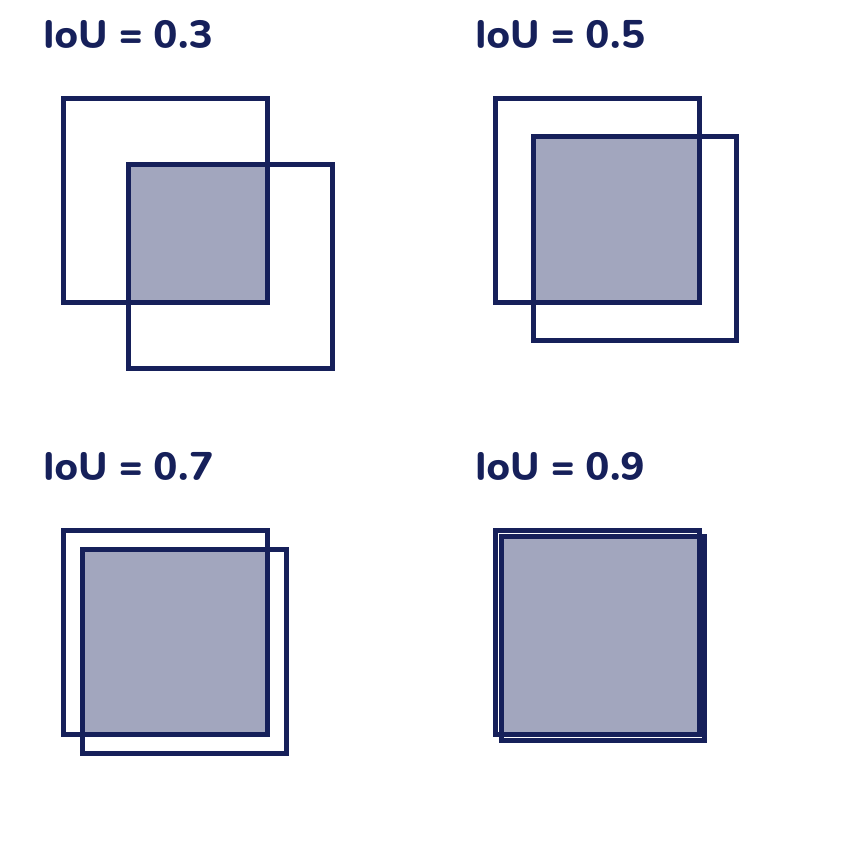

In [ ]:
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, t in zip(ejes.flat, [0.3, 0.5, 0.7, 0.9]):
    lado = np.sqrt(200 * t / (1 + t))     # lado de la intersección
    d = 10 - lado
    fija, corrida = [0, 0, 10, 10], [d, d, 10 + d, 10 + d]
    eje.add_patch(plt.Rectangle((d, d), lado, lado, color="C2", alpha=0.5))
    for c in [fija, corrida]:
        eje.add_patch(plt.Rectangle((c[0], c[1]), 10, 10, fill=False,
                                    edgecolor="C0", linewidth=2))
    eje.set_title(f"IoU = {iou(fija, corrida):.1f}")
    eje.set_xlim(-1, 16)
    eje.set_ylim(16, -1)
    eje.set_aspect("equal")
    eje.axis("off")
plt.show()

Fíjate en lo más importante: con IoU 0,5 las dos cajas se ven bastante distintas a ojo (la segunda está corrida apenas un 18 % de su lado en cada dirección), y aun así 0,5 es el umbral que se usa muchas veces para decir que una detección «acertó».

## Tres detectores en la misma foto

Un detector es una red convolucional (o un transformer) con dos salidas por cada objeto: **qué es** (una clasificación, como en el tema «Redes convolucionales») y **dónde está** (cuatro números de la caja, una regresión, como en el tema 6). Vamos a comparar tres, todos entrenados con **COCO**, un conjunto de unas 118 000 fotos con 80 clases de objetos cotidianos (personas, autos, buses, semáforos, perros, tazas…):

- **Faster R-CNN** (versión liviana con MobileNet v3, a 320 píxeles): detector de **dos etapas**. La primera propone regiones donde «parece haber algo»; la segunda clasifica cada región y ajusta su caja.
- **SSDlite** (también con MobileNet v3, a 320 × 320): detector de **una etapa**. Una sola pasada de la red predice, para una rejilla de cajas de referencia (*anclas*) de varios tamaños, si hay un objeto y cómo corregir el ancla. La familia **YOLO** (*You Only Look Once*), que nació casi al mismo tiempo, también es de una etapa. La versión más conocida hoy, la de Ultralytics, tiene licencia AGPL-3.0, que obligaría a publicar con esa misma licencia el código de cualquier programa que la incluya y se comparta; por eso aquí usamos detectores con licencias que no imponen eso.
- **DETR** (de Facebook, con una ResNet-50): un **transformer**. Lo vemos en detalle más abajo.

Los dos primeros vienen en `torchvision` (código con licencia BSD-3). Sus pesos se entrenaron con COCO, cuyas anotaciones son CC BY 4.0. La primera vez se bajan 14 MB y 81 MB.

In [ ]:
from torchvision.models import detection
from torchvision.transforms.functional import to_tensor

pesos_frcnn = detection.FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT
frcnn = detection.fasterrcnn_mobilenet_v3_large_320_fpn(weights=pesos_frcnn)
frcnn = frcnn.to(device).eval()
pesos_ssd = detection.SSDLite320_MobileNet_V3_Large_Weights.DEFAULT
ssd = detection.ssdlite320_mobilenet_v3_large(weights=pesos_ssd)
ssd = ssd.to(device).eval()
# Los nombres de las clases de COCO, en inglés
CLASES = pesos_frcnn.meta["categories"]


def detectar(modelo, foto, umbral=0.5):
    """Cajas (xyxy, en píxeles), clases y puntajes por encima del umbral."""
    # Los modelos de torchvision reciben una lista de imágenes 0-1
    x = to_tensor(foto).to(device)
    with torch.no_grad():
        salida = modelo([x])[0]
    deja = salida["scores"] >= umbral
    cajas = salida["boxes"][deja].cpu().numpy()
    clases = [CLASES[i] for i in salida["labels"][deja].tolist()]
    return cajas, clases, salida["scores"][deja].cpu().numpy()


resultados = {}
for nombre, modelo in [("SSDlite", ssd), ("Faster R-CNN", frcnn)]:
    resultados[nombre] = detectar(modelo, foto)
    millones = sum(p.numel() for p in modelo.parameters()) / 1e6
    cajas, clases, puntajes = resultados[nombre]
    print(f"{nombre} ({millones:.1f} M parámetros): {len(cajas)} objetos",
          dict(Counter(clases)))

SSDlite (3.4 M parámetros): 0 objetos {}
Faster R-CNN (19.4 M parámetros): 6 objetos {'car': 5, 'bicycle': 1}


SSDlite no ve **nada** con puntaje de 0,5 o más: reduce la foto a 320 × 320 y los autos quedan de pocos píxeles. Faster R-CNN ve 5 autos y una «bicicleta» que, como viste en la actividad, es el peatón.

DETR viene de Hugging Face (`facebook/detr-resnet-50`, licencia Apache-2.0, 167 MB). Su procesador prepara la imagen y después convierte la salida en cajas en píxeles; `transformers` necesita la librería `timm` para armar la ResNet-50.

In [ ]:
from transformers import AutoImageProcessor, AutoModelForObjectDetection

DETR = "facebook/detr-resnet-50"
procesador = AutoImageProcessor.from_pretrained(DETR)
detr = AutoModelForObjectDetection.from_pretrained(DETR).to(device).eval()


def detectar_detr(foto, umbral=0.7):
    """Lo mismo que detectar(), pero con DETR."""
    x = procesador(images=foto, return_tensors="pt").to(device)
    with torch.no_grad():
        salida = detr(**x)
    r = procesador.post_process_object_detection(
        salida, threshold=umbral, target_sizes=[foto.size[::-1]])[0]
    clases = [detr.config.id2label[i] for i in r["labels"].tolist()]
    return r["boxes"].cpu().numpy(), clases, r["scores"].cpu().numpy()


resultados["DETR"] = detectar_detr(foto)
millones = sum(p.numel() for p in detr.parameters()) / 1e6
cajas, clases, puntajes = resultados["DETR"]
print(f"DETR ({millones:.1f} M parámetros): {len(cajas)} objetos")
for clase, n in Counter(clases).most_common():
    print(f"  {clase}: {n}")

DETR (41.5 M parámetros): 41 objetos
  car: 17
  person: 13
  traffic light: 5
  bus: 2
  handbag: 2
  motorcycle: 1
  truck: 1


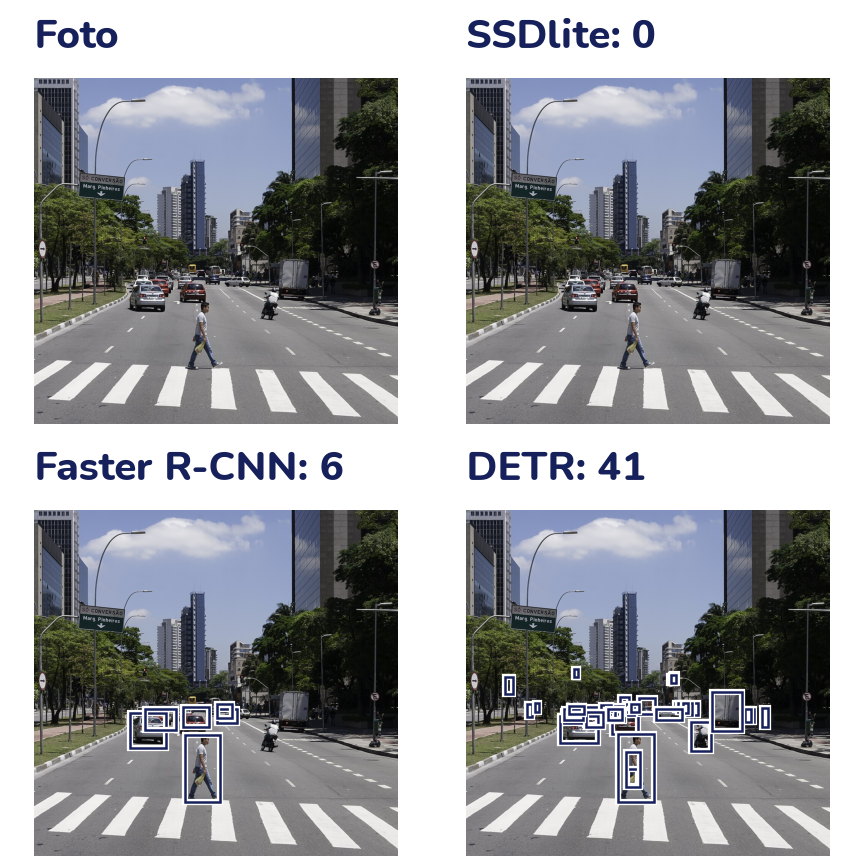

In [ ]:
def dibujar_cajas(eje, cajas, color="C0", ancho=1.5):
    for x1, y1, x2, y2 in cajas:
        # Un borde blanco debajo para que la caja se vea en cualquier fondo
        for c, a in [("white", ancho + 1.5), (color, ancho)]:
            eje.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                        fill=False, edgecolor=c,
                                        linewidth=a))


fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
ejes[0, 0].imshow(foto)
ejes[0, 0].set_title("Foto")
for eje, nombre in zip(ejes.flat[1:], resultados):
    eje.imshow(foto)
    dibujar_cajas(eje, resultados[nombre][0], ancho=1)
    eje.set_title(f"{nombre}: {len(resultados[nombre][0])}")
for eje in ejes.flat:
    eje.axis("off")
plt.show()

Los tres modelos ven cosas muy distintas en la misma foto. DETR encuentra mucho más, incluidos autos lejanos y semáforos de pocos píxeles, en buena parte porque trabaja con la imagen a 800 píxeles de alto en lugar de 320, y además porque es una red bastante más grande. ¿Y la velocidad? En la computadora donde escribimos este tema (CPU, dos hilos), una foto tardó unos 0,04 s con SSDlite, 0,05 s con Faster R-CNN y entre 0,3 y 0,6 s con DETR: **más de seis veces más lento**. Para medirlo en la tuya, guarda `time.perf_counter()` antes y después de la llamada y resta. Ese es el compromiso de siempre en detección: rapidez (para video en vivo, un teléfono) frente a calidad (objetos chicos, escenas llenas).

Los nombres de las 80 clases de COCO vienen fijos y en inglés: el modelo solo puede responder con ellos. Estos son los que usamos en el tema:

| Clase de COCO | En español |
| --- | --- |
| person | persona |
| car | auto |
| bus | bus |
| truck | camión |
| motorcycle | moto |
| traffic light | semáforo |

COCO no tiene una clase para los minibuses, trufis o micros: en una calle boliviana el detector los llamará «bus», «car» o «truck», o no los verá. Si grabas tu propia calle en el mini-proyecto, fíjate cómo los clasifica.

## Supresión de no máximos (NMS)

Faster R-CNN y SSD producen muchas cajas candidatas por objeto, y por dentro ya aplican NMS antes de devolverlas. Para ver qué pasa sin ella, la apagamos: el atributo `roi_heads.nms_thresh` es el umbral de IoU de la NMS de Faster R-CNN, y con 1,0 no borra nada (ningún par de cajas distintas tiene IoU mayor que 1).

In [ ]:
frcnn.roi_heads.nms_thresh = 1.0
crudas, clases_crudas, puntajes_crudos = detectar(frcnn, foto)
frcnn.roi_heads.nms_thresh = 0.5          # el valor que trae
print(len(crudas), "cajas con puntaje de 0,5 o más antes de NMS")

15 cajas con puntaje de 0,5 o más antes de NMS


La NMS es el algoritmo que jugaste en la actividad:

1. Ordenar las cajas de mayor a menor puntaje.
2. Quedarse con la primera (la de mayor puntaje).
3. Borrar todas las que tengan con ella un IoU **mayor** que el umbral: son el mismo objeto visto otra vez.
4. Repetir con las que quedan, hasta que no quede ninguna.

In [ ]:
def nms(cajas, puntajes, umbral_iou=0.5):
    """Índices de las cajas que sobreviven, de mayor a menor puntaje."""
    orden = list(np.argsort(-puntajes))     # de mayor a menor
    quedan = []
    while orden:
        mejor = orden.pop(0)
        quedan.append(mejor)
        # Sobreviven solo las que no se parecen demasiado a la mejor
        orden = [i for i in orden
                 if iou(cajas[mejor], cajas[i]) <= umbral_iou]
    return quedan


from torchvision.ops import nms as nms_torchvision

mias = nms(crudas, puntajes_crudos)
suyas = nms_torchvision(torch.tensor(crudas), torch.tensor(puntajes_crudos),
                        iou_threshold=0.5).tolist()
print("Quedan:", len(mias), "cajas:", [clases_crudas[i] for i in mias])
print("¿Igual que torchvision?", [int(i) for i in mias] == suyas)

Quedan: 6 cajas: ['car', 'car', 'car', 'bicycle', 'car', 'car']
¿Igual que torchvision? True


De 15 cajas quedan 6, las mismas que el modelo devolvió solo. Un detalle: la NMS de `torchvision` dentro del modelo trabaja **por clase** (una caja de «auto» no borra a una de «persona», aunque se crucen). Aquí no cambia nada, porque las cajas de clases distintas no se tocan; en el ejercicio 4 escribes la versión por clase.

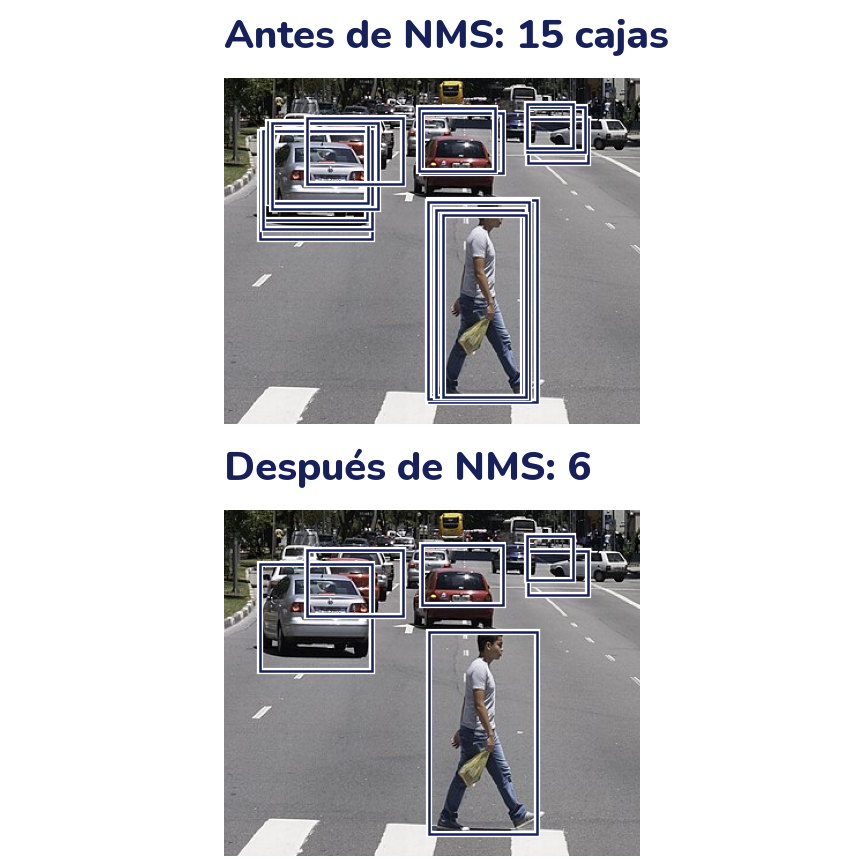

In [ ]:
fig, ejes = plt.subplots(2, 1, figsize=(4.8, 4.8))
for eje, cajas, titulo in [(ejes[0], crudas, "Antes de NMS: 15 cajas"),
                           (ejes[1], crudas[mias], "Después de NMS: 6")]:
    eje.imshow(foto)
    dibujar_cajas(eje, cajas, ancho=1)
    # Solo la parte de la foto donde están las cajas
    eje.set_xlim(220, 580)
    eje.set_ylim(790, 490)
    eje.set_title(titulo)
    eje.axis("off")
plt.show()

El umbral de IoU de la NMS es una perilla, como viste en la actividad. Muy bajo (0,2), borra objetos de verdad que están pegados, como dos autos en fila o personas en una multitud. Muy alto (0,8), deja pasar cajas repetidas y el mismo auto se cuenta dos veces.

## DETR: detectar sin NMS

DETR (*DEtection TRansformer*, 2020) cambia la forma de plantear el problema. Una CNN (la ResNet-50) convierte la imagen en un mapa de variables; cada posición de ese mapa es un token, como los parches del ViT del tema «Atención y transformers». Un transformer codificador-decodificador procesa esos tokens con atención, y el decodificador recibe **100 consultas aprendidas** (*object queries*). Ojo: no son las consultas Q del tema «Atención y transformers», que se calculan a partir de cada token. Son 100 vectores que la red aprende como cualquier peso y que entran al decodificador como si fueran tokens; cada uno «le pregunta» a la imagen, con atención cruzada, si hay un objeto y dónde: cada consulta es una «ranura» que termina describiendo un objeto o diciendo «aquí no hay nada».

In [ ]:
x = procesador(images=foto, return_tensors="pt").to(device)
with torch.no_grad():
    salida = detr(**x)
print("Imagen que entra:", tuple(x["pixel_values"].shape))
print("Clases por consulta:", tuple(salida.logits.shape))
print("Cajas por consulta:", tuple(salida.pred_boxes.shape))

# La última de las 92 columnas es «no hay objeto»
probabilidades = salida.logits.softmax(-1)[0]
nada = probabilidades[:, -1]
mejor_clase = probabilidades[:, :-1].max(dim=-1).values
print("Consultas que dicen «no hay objeto»:", int((nada >= 0.5).sum()))
print("Consultas con una clase de 0,7 o más:",
      int((mejor_clase >= 0.7).sum()))

Imagen que entra: (1, 3, 800, 838)
Clases por consulta: (1, 100, 92)
Cajas por consulta: (1, 100, 4)
Consultas que dicen «no hay objeto»: 39
Consultas con una clase de 0,7 o más: 41


Cada una de las 100 consultas da 92 puntajes: COCO numera sus 80 clases del 1 al 90 con huecos, así que hay 91 columnas para clases (del 0 al 90, algunas sin usar), más una de «no hay objeto» y una caja en formato cxcywh dividida por el tamaño de la imagen, que `post_process_object_detection` convierte a xyxy en píxeles. Las consultas con una clase de 0,7 o más son justo las 41 detecciones de antes.

Al entrenar, cada objeto real se empareja con **una sola** consulta (la que mejor le queda), y las demás aprenden a decir «no hay objeto». Si dos consultas describen el mismo objeto, una de ellas se castiga. Así las consultas aprenden a «repartirse» los objetos mirándose entre sí con autoatención, y DETR no trae NMS. ¿Funciona? Apliquémosle la NMS de `torchvision` por clase (`batched_nms`) a sus 41 cajas y veamos cuántas sobreviven, comparado con Faster R-CNN sin su NMS.

In [ ]:
from torchvision.ops import batched_nms

for nombre, (cajas, clases, puntajes) in [
        ("Faster R-CNN sin NMS", (crudas, clases_crudas, puntajes_crudos)),
        ("DETR", resultados["DETR"])]:
    # batched_nms necesita las clases como números
    codigos = torch.tensor([CLASES.index(c) for c in clases])
    quedan = batched_nms(torch.tensor(cajas), torch.tensor(puntajes),
                         codigos, iou_threshold=0.5)
    print(f"{nombre}: {len(cajas)} cajas, NMS deja {len(quedan)}")

Faster R-CNN sin NMS: 15 cajas, NMS deja 6
DETR: 41 cajas, NMS deja 36


En Faster R-CNN la NMS borra 9 de las 15 cajas: sin ella, cada auto se contaría dos o tres veces. En DETR borra 5 de 41. La mayoría de las consultas ya se repartieron bien los objetos; las 5 que caen son cajas encimadas en la fila de autos del fondo, donde un auto tapa a otro (algunas son repetidas y otras podrían ser dos autos de verdad: a ese tamaño ni a ojo es fácil decidir). DETR no es perfecto, pero ya no depende de una regla hecha a mano con un umbral que hay que elegir.

## El umbral de confianza

Cada detección trae un puntaje, y tú decides desde dónde creerle. Con un umbral bajo aparecen más objetos de verdad, pero también más falsas alarmas; con uno alto, las que quedan son confiables, pero se pierden objetos.

In [ ]:
cajas, clases, puntajes = detectar_detr(foto, umbral=0.3)
for umbral in [0.3, 0.5, 0.7, 0.9]:
    deja = puntajes >= umbral
    personas = sum(c == "person" for c, d in zip(clases, deja) if d)
    print(f"Umbral {umbral}: {deja.sum():2d} objetos, {personas} personas")

Umbral 0.3: 78 objetos, 27 personas
Umbral 0.5: 59 objetos, 20 personas
Umbral 0.7: 41 objetos, 13 personas
Umbral 0.9: 19 objetos, 2 personas


Es el mismo compromiso entre precisión y exhaustividad (*recall*) del tema «Evaluar bien»: subir el umbral sube la precisión y baja la exhaustividad. Para resumir un detector en un número sin elegir un umbral, se usa la **mAP** (*mean average precision*, «precisión promedio media»). Aquí no la calculamos, pero vas a leerla en las fichas de los modelos, así que conviene saber de dónde sale:

1. Se toman fotos con sus cajas correctas anotadas a mano, y las detecciones de una clase se ordenan de mayor a menor puntaje.
2. Una detección **acierta** si su IoU con una caja real de esa clase es de 0,5 o más (y esa caja real no fue usada por otra detección).
3. Para cada umbral se calculan la precisión (qué parte de las cajas que se creen aciertan) y la exhaustividad (qué parte de los objetos reales se encontraron).
4. Esos puntos forman la **curva precisión–exhaustividad** del tema «Evaluar bien». Su área es la **AP** (*average precision*, precisión promedio) de esa clase: 1 si el detector encuentra todo sin equivocarse.
5. La **mAP** es el promedio de las AP de todas las clases. La de COCO, además, repite la cuenta con umbrales de IoU de 0,5, 0,55, …, 0,95 y promedia: premia las cajas bien ajustadas, no solo las que más o menos aciertan.

## Video: una foto tras otra

Un video es una secuencia de fotos (**cuadros**) que se muestran rápido, por ejemplo 30 por segundo. Para un detector, procesar un video es procesar cuadros. La librería OpenCV (`cv2`) los lee uno por uno; ojo, los entrega en orden BGR (azul, verde, rojo) en lugar de RGB, así que hay que reordenarlos antes de pasarlos al modelo.

El video muestra el tráfico en una autopista de Chicago, grabado con cámara fija y acelerado 10 veces: «Congested traffic on the Dan Ryan Expy (10x timelapse) - April 2026», de AlphaBeta135, en [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Congested_traffic_on_the_Dan_Ryan_Expy_(10x_timelapse)_-_April_2026.webm), con licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0). Usamos la versión de 480p de Commons; en la figura le dibujamos cajas encima.

No hace falta detectar en los 30 cuadros de cada segundo: los autos casi no se mueven en un treintavo de segundo. Tomamos uno de cada 10 cuadros y contamos los vehículos (`car`, `bus` y `truck` en COCO) con Faster R-CNN.

In [ ]:
import cv2

VEHICULOS = {"car", "bus", "truck"}
video = cv2.VideoCapture(str(ruta_video))
fps = video.get(cv2.CAP_PROP_FPS)
tiempos, conteos = [], []
i = 0
while True:
    ok, cuadro = video.read()
    if not ok:                           # se acabó el video
        break
    if i % 10 == 0:
        rgb = cv2.cvtColor(cuadro, cv2.COLOR_BGR2RGB)
        cajas, clases, _ = detectar(frcnn, Image.fromarray(rgb))
        es_vehiculo = [c in VEHICULOS for c in clases]
        tiempos.append(i / fps)
        conteos.append(sum(es_vehiculo))
        if i == 180:                     # un cuadro para la figura
            ejemplo, cajas_ejemplo = rgb, cajas[es_vehiculo]
    i += 1
video.release()

print(f"{i} cuadros a {fps:.0f} por segundo ({i / fps:.1f} s); "
      f"analizamos {len(conteos)}")
print("Vehículos por cuadro: mínimo", min(conteos), "máximo", max(conteos),
      "mediana", np.median(conteos))

362 cuadros a 30 por segundo (12.1 s); analizamos 37
Vehículos por cuadro: mínimo 5 máximo 13 mediana 8.0


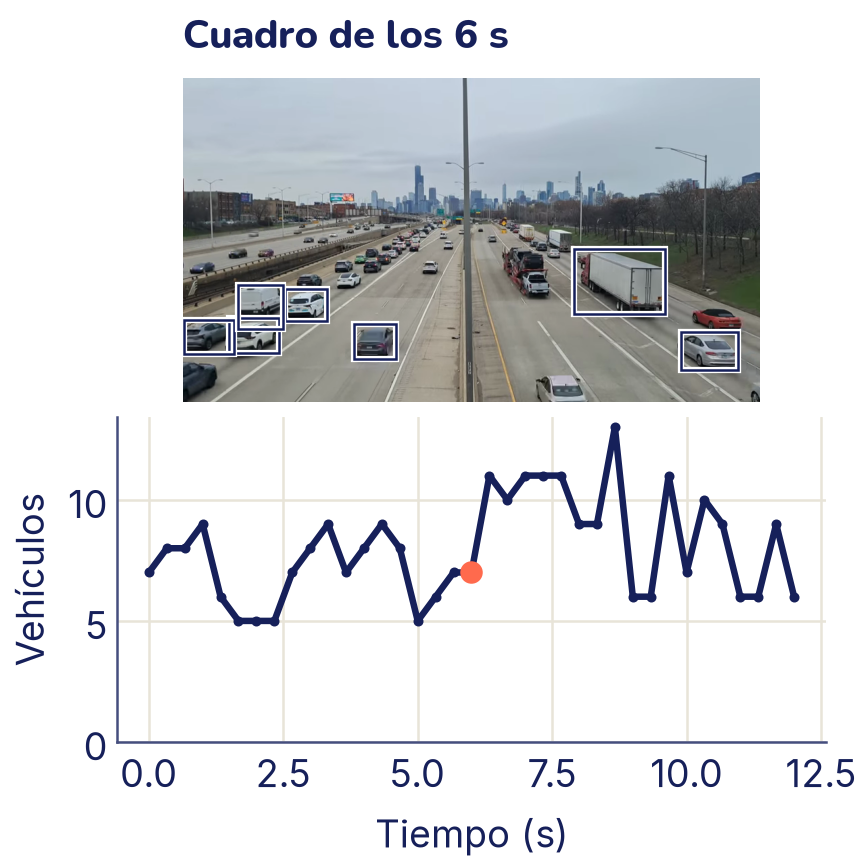

In [ ]:
fig, ejes = plt.subplots(2, 1, figsize=(4.8, 4.8))
ejes[0].imshow(ejemplo)
dibujar_cajas(ejes[0], cajas_ejemplo, ancho=1)
ejes[0].set_title(f"Cuadro de los {180 / fps:.0f} s")
ejes[0].axis("off")
ejes[1].plot(tiempos, conteos, color="C0", marker="o", markersize=3)
ejes[1].plot(180 / fps, conteos[18], "o", color="C1", markersize=8)
ejes[1].set_xlabel("Tiempo (s)")
ejes[1].set_ylabel("Vehículos")
ejes[1].set_ylim(0, None)
plt.show()

El conteo salta de un cuadro al siguiente aunque el tráfico casi no cambie, y en el cuadro de arriba hay muchos más autos que cajas: Faster R-CNN a 320 píxeles pierde los autos lejanos, igual que en la foto de la avenida. En el mini-proyecto comparas con DETR y resumes el conteo por segundo.

Ojo: contar vehículos **por cuadro** no es contar cuántos vehículos **pasaron**. El mismo auto aparece en muchos cuadros. Para eso hace falta **seguimiento** (*tracking*): unir las detecciones de un cuadro con las del siguiente, por ejemplo emparejando las cajas que tienen mayor IoU entre cuadros consecutivos, y dar a cada objeto un número que lo acompañe mientras está a la vista. Con eso se puede contar cuántos autos cruzan una línea. Los métodos de seguimiento más usados (como SORT y sus sucesores) agregan una predicción del movimiento de cada caja; no los programamos aquí, pero la base es el IoU que ya conoces.

## Segmentar: una clase por píxel

En la **segmentación semántica** la salida es una imagen del mismo tamaño que la entrada, donde cada píxel lleva su clase. Es como clasificar cada píxel. Necesitamos imágenes con su **máscara** correcta, y anotar máscaras a mano es carísimo. Para aprender, vamos a generar las nuestras: imágenes **sintéticas** de 48 × 48 con círculos y cuadrados sobre un fondo con ruido. Cada forma tiene un brillo al azar, así que la red no puede distinguir las clases por el color: tiene que mirar la **forma**.

In [ ]:
LADO = 48


def generar_formas(n, rng):
    """n imágenes de 48 x 48 con círculos y cuadrados, y sus máscaras."""
    yy, xx = np.mgrid[0:LADO, 0:LADO]
    imagenes = np.zeros((n, LADO, LADO), dtype=np.float32)
    mascaras = np.zeros((n, LADO, LADO), dtype=np.int64)
    for i in range(n):
        # Fondo oscuro con ruido
        imagen = rng.uniform(0, 0.4) + rng.normal(0, 0.08, (LADO, LADO))
        for _ in range(rng.integers(1, 4)):        # de 1 a 3 formas
            clase = rng.integers(1, 3)             # 1 círculo, 2 cuadrado
            r = rng.uniform(4, 9)
            cy, cx = rng.uniform(r, LADO - r, size=2)
            if clase == 1:
                dentro = (yy - cy) ** 2 + (xx - cx) ** 2 <= r ** 2
            else:
                dentro = ((abs(yy - cy) <= 0.85 * r)
                          & (abs(xx - cx) <= 0.85 * r))
            # Cada forma con su propio brillo, también con ruido
            imagen[dentro] = (rng.uniform(0.5, 1)
                              + rng.normal(0, 0.08, dentro.sum()))
            mascaras[i][dentro] = clase
        imagenes[i] = imagen
    return imagenes, mascaras


rng = np.random.default_rng(42)
X_ent, Y_ent = generar_formas(1000, rng)
X_val, Y_val = generar_formas(200, rng)
print("Imágenes:", X_ent.shape, " máscaras:", Y_ent.shape)
for clase, nombre in enumerate(["fondo", "círculo", "cuadrado"]):
    print(f"Píxeles de {nombre}: {(Y_ent == clase).mean():.1%}")

Imágenes: (1000, 48, 48)  máscaras: (1000, 48, 48)
Píxeles de fondo: 89.2%
Píxeles de círculo: 5.5%
Píxeles de cuadrado: 5.3%


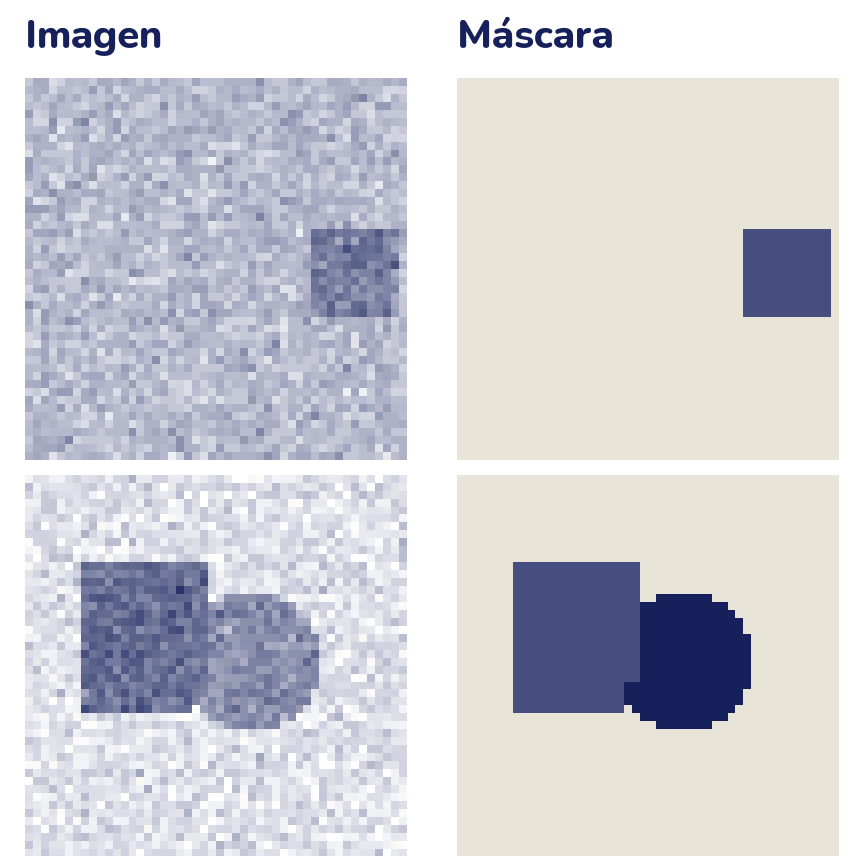

In [ ]:
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

blanco_tinta = LinearSegmentedColormap.from_list("bt", ["white", "C0"])
# Fondo, círculo y cuadrado, cada uno con su color
colores_mascara = ListedColormap(["C3", "C0", "C2"])

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for fila, k in enumerate([0, 1]):
    ejes[fila, 0].imshow(X_ent[k], cmap=blanco_tinta, vmin=0, vmax=1)
    ejes[fila, 1].imshow(Y_ent[k], cmap=colores_mascara, vmin=0, vmax=2)
ejes[0, 0].set_title("Imagen")
ejes[0, 1].set_title("Máscara")
for eje in ejes.flat:
    eje.axis("off")
plt.show()

Fíjate en el **desbalance**: el 89 % de los píxeles son fondo. Un «modelo» que diga siempre «fondo» acierta el 89 % de los píxeles sin ver nada. Por eso en segmentación la exactitud por píxel engaña y se mide por clase, con el IoU de las máscaras.

## La U-Net

Para clasificar una imagen, una CNN la va achicando con pooling hasta quedarse con unos pocos números: gana contexto (sabe «qué hay») y pierde detalle (no sabe en qué píxel). Para segmentar necesitamos las dos cosas. La **U-Net** (2015, pensada para imágenes médicas) lo resuelve con tres piezas:

- un **codificador**, como una CNN normal: convoluciones y pooling que bajan la resolución (48 → 24 → 12) y suben los canales;
- un **decodificador** que vuelve a subir la resolución (12 → 24 → 48) con **convoluciones transpuestas** (`nn.ConvTranspose2d`), que hacen lo contrario de un pooling: de cada píxel salen 2 × 2;
- **conexiones de salto**: en cada nivel, el decodificador pega (`torch.cat`) los mapas del codificador del mismo tamaño. Así recupera los bordes finos que se perdieron al bajar.

Dibujada, la red tiene forma de U: baja por la izquierda, sube por la derecha y los saltos cruzan de un lado al otro. La última capa es una convolución 1 × 1 que da, para cada píxel, un puntaje por clase. Una convolución 1 × 1 no mira a los vecinos: en cada píxel combina sus canales en un puntaje por clase, como una capa lineal aplicada píxel por píxel.

In [ ]:
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


def doble_conv(entrada, salida):
    """Dos convoluciones 3 x 3, cada una con BatchNorm y ReLU."""
    return nn.Sequential(
        nn.Conv2d(entrada, salida, 3, padding=1), nn.BatchNorm2d(salida),
        nn.ReLU(),
        nn.Conv2d(salida, salida, 3, padding=1), nn.BatchNorm2d(salida),
        nn.ReLU())


class UNet(nn.Module):
    def __init__(self, clases=3):
        super().__init__()
        self.bajar = nn.MaxPool2d(2)
        # Codificador: 48 x 48, 24 x 24 y 12 x 12
        self.cod1 = doble_conv(1, 8)
        self.cod2 = doble_conv(8, 16)
        self.centro = doble_conv(16, 32)
        # Decodificador: sube y junta lo del codificador
        self.subir2 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec2 = doble_conv(16 + 16, 16)
        self.subir1 = nn.ConvTranspose2d(16, 8, 2, stride=2)
        self.dec1 = doble_conv(8 + 8, 8)
        self.salida = nn.Conv2d(8, clases, 1)

    def forward(self, x):
        c1 = self.cod1(x)                       # (8, 48, 48)
        c2 = self.cod2(self.bajar(c1))          # (16, 24, 24)
        centro = self.centro(self.bajar(c2))    # (32, 12, 12)
        # Conexiones de salto: se pegan los canales del codificador
        d2 = self.dec2(torch.cat([self.subir2(centro), c2], dim=1))
        d1 = self.dec1(torch.cat([self.subir1(d2), c1], dim=1))
        return self.salida(d1)                  # (3, 48, 48)


torch.manual_seed(0)
unet = UNet().to(device)
x_val = torch.tensor(X_val).unsqueeze(1).to(device)   # (200, 1, 48, 48)
y_val = torch.tensor(Y_val).to(device)
print("Salida:", tuple(unet(x_val[:2]).shape))
print("Parámetros:", sum(p.numel() for p in unet.parameters()))

Salida: (2, 3, 48, 48)
Parámetros: 29659


Para cada una de las 2 imágenes salen 3 mapas de 48 × 48: el puntaje de cada clase en cada píxel. La pérdida es la misma **entropía cruzada** de la clasificación, pero aplicada en cada píxel y promediada: `nn.CrossEntropyLoss` acepta directamente salidas de forma (lote, clases, alto, ancho) y máscaras de forma (lote, alto, ancho).

El bucle es el del tema 18, con un cambio: en lugar de la exactitud medimos el **IoU de cada clase** sobre las imágenes de validación (todos los píxeles de esa clase juntos). Guardamos además la predicción para la primera imagen de validación después de cada época, para ver cómo aprende.

In [ ]:
def predecir_mascaras(modelo, x):
    modelo.eval()
    with torch.no_grad():
        return modelo(x).argmax(dim=1)          # la clase con más puntaje


def iou_clases(pred, real, clases=3):
    """IoU de las máscaras de cada clase."""
    return [((pred == c) & (real == c)).sum().item()
            / ((pred == c) | (real == c)).sum().item()
            for c in range(clases)]


cargador = DataLoader(
    TensorDataset(torch.tensor(X_ent).unsqueeze(1), torch.tensor(Y_ent)),
    batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(0))
optimizador = torch.optim.Adam(unet.parameters(), lr=3e-3)
perdida_pixel = nn.CrossEntropyLoss()

historia = {0: predecir_mascaras(unet, x_val[:1])[0].cpu()}
for epoca in range(1, 9):
    unet.train()
    suma = 0.0
    for x, y in cargador:
        x, y = x.to(device), y.to(device)
        optimizador.zero_grad()
        perdida = perdida_pixel(unet(x), y)
        perdida.backward()
        optimizador.step()
        suma += perdida.item() * len(x)
    pred = predecir_mascaras(unet, x_val)
    historia[epoca] = pred[0].cpu()
    fondo, circulo, cuadrado = iou_clases(pred, y_val)
    print(f"Época {epoca}: pérdida {suma / len(X_ent):.3f}, IoU círculo "
          f"{circulo:.2f}, cuadrado {cuadrado:.2f}, fondo {fondo:.2f}")

Época 1: pérdida 0.796, IoU círculo 0.44, cuadrado 0.17, fondo 0.99
Época 2: pérdida 0.444, IoU círculo 0.08, cuadrado 0.43, fondo 0.99
Época 3: pérdida 0.245, IoU círculo 0.46, cuadrado 0.28, fondo 1.00
Época 4: pérdida 0.159, IoU círculo 0.60, cuadrado 0.56, fondo 1.00
Época 5: pérdida 0.104, IoU círculo 0.87, cuadrado 0.85, fondo 0.99
Época 6: pérdida 0.065, IoU círculo 0.86, cuadrado 0.85, fondo 0.99
Época 7: pérdida 0.046, IoU círculo 0.90, cuadrado 0.91, fondo 1.00
Época 8: pérdida 0.033, IoU círculo 0.94, cuadrado 0.94, fondo 1.00


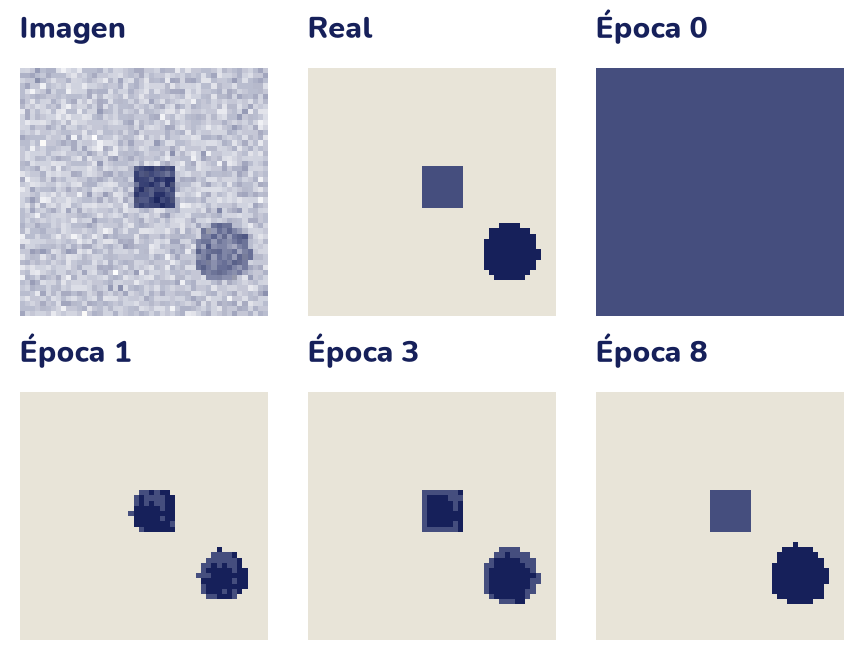

In [ ]:
fig, ejes = plt.subplots(2, 3, figsize=(4.8, 3.6))
ejes[0, 0].imshow(X_val[0], cmap=blanco_tinta, vmin=0, vmax=1)
ejes[0, 0].set_title("Imagen", fontsize=12)
ejes[0, 1].imshow(Y_val[0], cmap=colores_mascara, vmin=0, vmax=2)
ejes[0, 1].set_title("Real", fontsize=12)
for eje, epoca in zip(ejes.flat[2:], [0, 1, 3, 8]):
    eje.imshow(historia[epoca], cmap=colores_mascara, vmin=0, vmax=2)
    eje.set_title(f"Época {epoca}", fontsize=12)
for eje in ejes.flat:
    eje.axis("off")
plt.show()

Sin entrenar, la red dice «cuadrado» en todos los píxeles: sus pesos son aleatorios. Después de una época ya separa las formas del fondo, pero llama «círculo» a casi todo. El IoU del fondo es 0,99 desde la primera época, aunque la red todavía no sabe distinguir las formas: otra vez el desbalance. El de las formas sube a saltos (el del círculo cae a 0,08 en la época 2 antes de subir), algo común mientras la red todavía no decide qué rasgo separa las clases; en la época 3 se ve que el borde de un cuadrado ya es «cuadrado» pero su centro todavía es «círculo». Tras 8 épocas, unos 30 segundos en una CPU, las dos formas llegan a un IoU de 0,94.

Midamos el resultado con las 200 imágenes de validación, comparando con el «modelo» que dice siempre «fondo»:

In [ ]:
def dice_clase(pred, real, c):
    """Coeficiente de Dice de la clase c."""
    interseccion = ((pred == c) & (real == c)).sum().item()
    return 2 * interseccion / ((pred == c).sum().item()
                               + (real == c).sum().item())


pred = predecir_mascaras(unet, x_val)
print(f"Exactitud por píxel de la U-Net: "
      f"{(pred == y_val).float().mean():.3f}")
print(f"Exactitud de decir siempre «fondo»: {(y_val == 0).float().mean():.3f}")
for c, nombre in [(1, "círculo"), (2, "cuadrado")]:
    print(f"{nombre}: IoU {iou_clases(pred, y_val)[c]:.3f}, "
          f"Dice {dice_clase(pred, y_val, c):.3f}")

Exactitud por píxel de la U-Net: 0.996
Exactitud de decir siempre «fondo»: 0.896
círculo: IoU 0.937, Dice 0.968
cuadrado: IoU 0.938, Dice 0.968


La exactitud por píxel de la U-Net es 0,996, pero decir siempre «fondo» ya da 0,896: la diferencia parece chica y es enorme. El IoU de las formas, 0,94, sí dice lo que importa: de los píxeles que la red o la máscara real llaman «círculo», el 94 % coincide.

El **coeficiente de Dice** es otra forma de medir la superposición de dos máscaras: el doble de la intersección dividido por la suma de las dos áreas.

$$\mathrm{Dice} ( A , B ) = \frac{2 \cdot | A \cap B |}{| A | + | B |}$$

Aquí |*A*| es la cantidad de píxeles de la máscara *A*. Siempre da un poco más que el IoU (salvo en 0 y 1), y los dos ordenan igual a los modelos: el que tiene mejor IoU también tiene mejor Dice. Cuando el objeto ocupa muy pocos píxeles, también se usa como **pérdida** (1 − Dice, calculado con las probabilidades en lugar de las clases), sola o sumada a la entropía cruzada: a diferencia de la entropía cruzada por píxel, no se deja dominar por los miles de píxeles de fondo.

## Aumentar datos sin romper las etiquetas

En el tema «Redes convolucionales» aumentaste datos volteando y recortando imágenes. En detección y segmentación hay una trampa: si volteas la imagen, **la caja y la máscara también tienen que voltearse**, o la etiqueta queda apuntando al lugar equivocado. Al voltear horizontalmente una imagen de ancho *W*, el borde izquierdo de una caja pasa a ser *W* − *x*₂ y el derecho *W* − *x*₁. Las transformaciones de `torchvision.transforms.v2` lo hacen solas si les dices qué es cada cosa:

In [ ]:
from torchvision import tv_tensors
from torchvision.transforms import v2

imagen = tv_tensors.Image(torch.tensor(X_val[:1]))
mascara = tv_tensors.Mask(torch.tensor(Y_val[0]))
caja = tv_tensors.BoundingBoxes([[10, 5, 20, 15]], format="XYXY",
                                canvas_size=(LADO, LADO))

voltear = v2.RandomHorizontalFlip(p=1)    # p=1: voltea siempre
imagen_v, mascara_v, caja_v = voltear(imagen, mascara, caja)
print("Caja a mano:", [LADO - 20, 5, LADO - 10, 15])
print("Caja con v2:", caja_v.tolist()[0])
print("¿La máscara se volteó igual que la imagen?",
      torch.equal(mascara_v, mascara.flip(-1)))

Caja a mano: [28, 5, 38, 15]
Caja con v2: [28, 5, 38, 15]
¿La máscara se volteó igual que la imagen? True


## Más allá: instancias y seguimiento

- **Segmentación de instancias.** Junta detección y segmentación: para cada objeto detectado da una caja, una clase y su propia máscara. El modelo clásico, **Mask R-CNN**, es un Faster R-CNN con una pequeña red convolucional extra que pinta la máscara dentro de cada caja (`torchvision` trae `maskrcnn_resnet50_fpn`). Con eso se pueden separar dos personas que se tocan, o medir el área de cada hoja de una planta.
- **Seguimiento en video.** Detectar cuadro por cuadro y unir las detecciones en el tiempo, como viste en la sección del video, para contar objetos distintos, medir velocidades o saber cuánto tiempo estuvo alguien en un lugar.
- **Segmentar cualquier cosa.** Hay modelos grandes que segmentan objetos que nunca vieron con solo tocar un punto de la imagen (como SAM, de Meta) o a partir de una frase. Son el equivalente de CLIP para la segmentación.

Detectar y seguir personas con cámaras toca la **privacidad**: las mismas técnicas que cuentan autos sirven para vigilar a la gente. Si grabas un video para el mini-proyecto, que sea de un lugar público sin personas reconocibles en primer plano, o pide permiso.

## Lo que aprendiste y lo que sigue

- **Detectar** es decir qué hay y dónde, con cajas; **segmentar** es dar una clase a cada píxel (semántica) o una máscara a cada objeto (instancias).
- Una caja son cuatro números, en **xyxy** o en **xywh**; mezclarlos no da error, pero arruina todo.
- El **IoU** mide cuánto se superponen dos cajas o dos máscaras: intersección dividida por unión.
- Los detectores dan muchas cajas candidatas con su **puntaje**; el **umbral de confianza** decide cuáles creer y la **NMS** borra las repetidas. DETR, un transformer, no necesita NMS.
- Hay que elegir entre rapidez (SSDlite, Faster R-CNN liviano) y calidad en objetos chicos (DETR).
- Un **video** se procesa como una secuencia de cuadros; contar por cuadro no es seguir objetos.
- La **U-Net** combina un codificador, un decodificador y **conexiones de salto**; se entrena con entropía cruzada por píxel y se mide con IoU o Dice, porque el fondo domina.

En el próximo tema la entrada deja de ser una imagen: el sonido también se convierte en una «imagen» (el espectrograma) que una CNN puede mirar.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `foto`, `ruta_video`, `iou`, `iou_matriz`, `nms`, `detectar`, `detectar_detr`, `frcnn`, `CLASES`, `crudas`, `clases_crudas`, `puntajes_crudos`, `resultados`, `UNet`, `doble_conv`, `predecir_mascaras`, `iou_clases`, `dice_clase`, `cargador`, `x_val`, `y_val` y `unet`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. IoU a mano

Calcula sin computadora el IoU de la caja A = [2, 2, 6, 6] (en formato xyxy) con cada una de estas:

1. B = [4, 4, 8, 8]
2. C = [3, 2, 7, 6]
3. D = [6, 2, 10, 6]

Después compruébalo con la función `iou` de la teoría.

<details>
<summary>Respuesta</summary>

A mide 4 × 4, así que su área es 16; las otras tres también.

1. La intersección es [4, 4, 6, 6], de 2 × 2 = 4. La unión es 16 + 16 − 4 = 28. IoU = 4 / 28 ≈ **0,143**. Correr una caja la mitad de su lado en las dos direcciones deja muy poco IoU.
2. La intersección es [3, 2, 6, 6], de 3 × 4 = 12. La unión es 16 + 16 − 12 = 20. IoU = 12 / 20 = **0,6**.
3. La intersección sería [6, 2, 6, 6]: ancho 0. Las cajas solo comparten un borde, así que el IoU es **0**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
A = [2, 2, 6, 6]
for nombre, otra in [("B", [4, 4, 8, 8]), ("C", [3, 2, 7, 6]),
                     ("D", [6, 2, 10, 6])]:
    print(f"IoU(A, {nombre}) = {iou(A, otra):.3f}")

### 2. Formatos mezclados

Una persona anotó a mano el auto plateado de la foto con la caja [251, 536, 97, 93], en formato **xywh**. Faster R-CNN lo detectó con la caja [254, 535, 344, 613], en **xyxy**. Calcula el IoU entre las dos sin convertir la anotación y después convirtiéndola. ¿Qué concluirías en cada caso? Usa `box_convert` de `torchvision.ops` para convertir.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from torchvision.ops import box_convert

anotada_xywh = torch.tensor([[251., 536., 97., 93.]])
detectada = [254, 535, 344, 613]

mal = iou(anotada_xywh[0].tolist(), detectada)
anotada = box_convert(anotada_xywh, in_fmt="xywh", out_fmt="xyxy")
bien = iou(anotada[0].tolist(), detectada)
print("Anotación convertida:", anotada[0].tolist())
print(f"IoU sin convertir: {mal:.3f}")
print(f"IoU convirtiendo:  {bien:.3f}")

<details>
<summary>Respuesta</summary>

Sin convertir, la anotación se lee como una caja «al revés» (su *x*₂ = 97 queda a la izquierda de su *x*₁ = 251), y el IoU da 0: concluirías que el detector falló. Convirtiendo, el IoU es 0,761: un acierto claro (pasa con holgura el 0,5 de costumbre). El código no avisa nada en ninguno de los dos casos; por eso conviene dibujar las cajas sobre la foto antes de confiar en un número.

</details>

### 3. NMS a mano

Un detector devuelve cinco cajas de la misma clase:

| Caja | xyxy | Puntaje |
|---|---|---|
| A | [0, 0, 10, 10] | 0,90 |
| B | [1, 1, 11, 11] | 0,80 |
| C | [20, 0, 30, 10] | 0,75 |
| D | [0, 2, 10, 12] | 0,60 |
| E | [22, 1, 32, 11] | 0,30 |

Aplica NMS a mano con umbral de IoU 0,5 y después con 0,6. ¿Qué cajas quedan en cada caso? Pista: calcula primero los IoU de A con B y con D, y de C con E.

<details>
<summary>Respuesta</summary>

Los IoU que importan (todas las cajas tienen área 100):

- A y B se cruzan en [1, 1, 10, 10], de 9 × 9 = 81: IoU = 81 / (200 − 81) ≈ 0,68.
- A y D se cruzan en [0, 2, 10, 10], de 10 × 8 = 80: IoU = 80 / 120 ≈ 0,67.
- C y E se cruzan en [22, 1, 30, 10], de 8 × 9 = 72: IoU = 72 / 128 ≈ 0,56.
- A, B y D no tocan a C ni a E.

**Con umbral 0,5.** Se queda A (0,90) y borra B y D, que pasan de 0,5. Quedan C y E: se queda C y borra E (0,56). Resultado: **A y C**.

**Con umbral 0,6.** Se queda A y borra B y D, como antes. Se queda C, pero E (0,56) ya no pasa de 0,6 y sobrevive. Resultado: **A, C y E**. Si E es una segunda caja sobre el mismo objeto que C, ese objeto se contaría dos veces.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
cinco = np.array([[0, 0, 10, 10], [1, 1, 11, 11], [20, 0, 30, 10],
                  [0, 2, 10, 12], [22, 1, 32, 11]], dtype=float)
puntajes5 = np.array([0.90, 0.80, 0.75, 0.60, 0.30])
letras = "ABCDE"
print(np.round(iou_matriz(cinco, cinco), 2))
for umbral in [0.5, 0.6]:
    quedan = nms(cinco, puntajes5, umbral)
    print(f"Umbral {umbral}:", [letras[i] for i in quedan])

### 4. NMS por clase

La función `nms` de la teoría trata todas las cajas igual: una caja de «persona» podría borrar una de «bicicleta» si se cruzan mucho, aunque sean dos objetos distintos (una persona montada en su bicicleta). Escribe `nms_por_clase(cajas, puntajes, clases, umbral_iou)` que aplique `nms` por separado a cada clase y devuelva los índices que quedan, de mayor a menor puntaje. Compárala con `batched_nms` de `torchvision.ops` en las 15 cajas crudas de Faster R-CNN y en las 41 de DETR.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from torchvision.ops import batched_nms


def nms_por_clase(cajas, puntajes, clases, umbral_iou=0.5):
    quedan = []
    for clase in set(clases):
        # Los índices de las cajas de esta clase
        indices = np.array([i for i, c in enumerate(clases) if c == clase])
        for j in nms(cajas[indices], puntajes[indices], umbral_iou):
            quedan.append(int(indices[j]))
    return sorted(quedan, key=lambda i: -puntajes[i])


for nombre, (cajas, clases, puntajes) in [
        ("Faster R-CNN", (crudas, clases_crudas, puntajes_crudos)),
        ("DETR", resultados["DETR"])]:
    mias = nms_por_clase(cajas, puntajes, clases)
    codigos = torch.tensor([CLASES.index(c) for c in clases])
    suyas = batched_nms(torch.tensor(cajas), torch.tensor(puntajes),
                        codigos, 0.5).tolist()
    print(f"{nombre}: quedan {len(mias)}; ¿igual que torchvision?",
          mias == suyas)

<details>
<summary>Respuesta</summary>

`nms` recibe solo las cajas de una clase, así que los índices que devuelve son posiciones dentro de `indices`; hay que traducirlos con `indices[j]` a posiciones de la lista completa. Ese es el error más común al escribir esta función.

</details>

### 5. Elegir los umbrales

Para cada caso, ¿pondrías el umbral de confianza alto o bajo? ¿Y el umbral de IoU de la NMS? Explica qué error es más caro en cada uno.

1. Contar cuántas personas cruzan una plaza cada hora, para una estadística de la municipalidad.
2. Detectar baches en las fotos de una cámara montada en un auto, para mandar una cuadrilla a repararlos.

<details>
<summary>Respuesta</summary>

1. **Contar personas.** Aquí los dos errores pesan parecido: una falsa alarma suma una persona de más y una persona perdida, una de menos. Conviene un umbral de confianza intermedio (alrededor de 0,5 o 0,7) y elegirlo comparando con conteos hechos a mano en algunos cuadros. El umbral de IoU de la NMS no debe ser bajo: en una plaza la gente camina en grupos, sus cajas se cruzan, y con un umbral bajo la NMS borraría personas de verdad. Además, para contar personas distintas hace falta seguimiento, no solo contar por cuadro.
2. **Baches.** Perder un bache es caro (un accidente, una rueda rota) y una falsa alarma cuesta poco si una persona revisa la foto antes de mandar a la cuadrilla. Conviene un umbral de confianza **bajo** (más exhaustividad) y una revisión humana. Hay un problema previo: COCO no tiene la clase «bache», así que ninguno de los detectores del tema lo encuentra. Habría que anotar fotos propias y ajustar un detector, como hiciste con los modelos preentrenados en el tema «Visión moderna».

</details>

### 6. La exactitud que engaña

Calcula la exactitud por píxel y el IoU de cada clase de un «modelo» que responde «fondo» en todos los píxeles de las imágenes de validación. Compáralos con los de la U-Net entrenada. ¿Cuál de las dos medidas te habría alertado?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
todo_fondo = torch.zeros_like(y_val)
pred = predecir_mascaras(unet, x_val)
for nombre, p in [("Siempre fondo", todo_fondo), ("U-Net", pred)]:
    exactitud = (p == y_val).float().mean().item()
    fondo, circulo, cuadrado = iou_clases(p, y_val)
    print(f"{nombre}: exactitud {exactitud:.3f}, IoU fondo {fondo:.2f}, "
          f"círculo {circulo:.2f}, cuadrado {cuadrado:.2f}")

<details>
<summary>Respuesta</summary>

Con la exactitud por píxel, el modelo que no ve nada saca 0,896, cerca del 0,996 de la U-Net. Con el IoU de las formas, saca 0: no encontró ningún círculo ni cuadrado. El IoU por clase (o el Dice) es el que alerta. Fíjate en que el IoU del fondo también es alto para los dos: por eso se mira cada clase, y no solo el promedio.

</details>

### 7. Dice e IoU

1. Demuestra que, para dos máscaras cualesquiera, Dice = 2 · IoU / (1 + IoU). Pista: llama *I* a la intersección y *U* a la unión, y recuerda que |*A*| + |*B*| = *U* + *I*.
2. Comprueba la fórmula con los valores de la U-Net para el círculo.
3. ¿Puede un modelo tener mejor IoU que otro y peor Dice?

<details>
<summary>Respuesta</summary>

1. IoU = *I* / *U*, y Dice = 2*I* / (|*A*| + |*B*|) = 2*I* / (*U* + *I*). Dividiendo arriba y abajo por *U*: Dice = 2 (*I*/*U*) / (1 + *I*/*U*) = 2 · IoU / (1 + IoU).
2. Con el código:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
iou_c = iou_clases(pred, y_val)[1]
print(f"IoU del círculo: {iou_c:.4f}")
print(f"2·IoU/(1 + IoU): {2 * iou_c / (1 + iou_c):.4f}")
print(f"Dice calculado:  {dice_clase(pred, y_val, 1):.4f}")

<details>
<summary>Respuesta (sigue)</summary>

3. No. La función 2*x* / (1 + *x*) crece siempre entre 0 y 1, así que si un modelo tiene mayor IoU que otro en una clase, también tiene mayor Dice. Las dos medidas ordenan igual a los modelos de una clase; solo cambia la escala (el Dice da números más altos). Al promediar varias clases o varias imágenes sí pueden ordenar distinto, porque el promedio de los Dice no es el Dice del promedio.

</details>

### 8. Una U-Net sin saltos

Copia la U-Net quitando las conexiones de salto: el decodificador solo recibe lo que sube del nivel de abajo. Entrénala 8 épocas como en la teoría y compara el IoU final de las formas. ¿Qué crees que pierde?

<details>
<summary>Respuesta</summary>

Sin `torch.cat`, cada `doble_conv` del decodificador recibe la mitad de canales.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
class UNetSinSaltos(UNet):
    def __init__(self, clases=3):
        super().__init__(clases)
        self.dec2 = doble_conv(16, 16)
        self.dec1 = doble_conv(8, 8)

    def forward(self, x):
        c1 = self.cod1(x)
        c2 = self.cod2(self.bajar(c1))
        centro = self.centro(self.bajar(c2))
        d2 = self.dec2(self.subir2(centro))       # sin c2
        d1 = self.dec1(self.subir1(d2))           # sin c1
        return self.salida(d1)


torch.manual_seed(0)
sin_saltos = UNetSinSaltos().to(device)
optimizador = torch.optim.Adam(sin_saltos.parameters(), lr=3e-3)
for epoca in range(1, 9):
    sin_saltos.train()
    for x, y in cargador:
        x, y = x.to(device), y.to(device)
        optimizador.zero_grad()
        perdida = nn.CrossEntropyLoss()(sin_saltos(x), y)
        perdida.backward()
        optimizador.step()

for nombre, modelo in [("Con saltos", unet), ("Sin saltos", sin_saltos)]:
    _, circulo, cuadrado = iou_clases(predecir_mascaras(modelo, x_val),
                                      y_val)
    print(f"{nombre}: IoU círculo {circulo:.2f}, cuadrado {cuadrado:.2f}")

<details>
<summary>Respuesta (sigue)</summary>

Sin saltos, el IoU baja de 0,94 a 0,90 en los círculos y a 0,92 en los cuadrados. La diferencia es chica porque nuestras formas son simples y la red baja solo dos veces de resolución (hasta 12 × 12). Aun así, sin saltos el decodificador tiene que reconstruir el contorno exacto de cada forma a partir de ese mapa chico, y lo esperable es que los errores se junten en los bordes: compruébalo dibujando las predicciones de los dos modelos para la misma imagen. En imágenes reales, con bordes finos y más bajadas de resolución, los saltos hacen una diferencia mucho mayor.

</details>

### 9. Encuentra el error

Alguien quiere comparar con `torchvision` el IoU de dos cajas que tiene en NumPy y escribe esto. ¿Qué falla y cómo se arregla?

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
from torchvision.ops import box_iou

caja_a = np.array([[0, 0, 10, 10]], dtype=float)
caja_b = np.array([[5, 0, 15, 10]], dtype=float)
print(box_iou(caja_a, caja_b))

Traceback (most recent call last):
  ...
AttributeError: 'numpy.ndarray' object has no attribute 'is_floating_point'


<details>
<summary>Respuesta</summary>

Las funciones de `torchvision.ops` (`box_iou`, `nms`, `batched_nms`, `box_convert`) trabajan con **tensores** de PyTorch, no con arreglos de NumPy. El mensaje lo dice a su manera: buscó un método de los tensores (`is_floating_point`) en un `numpy.ndarray`. Se arregla convirtiendo con `torch.tensor` (o `torch.from_numpy`):

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print(box_iou(torch.tensor(caja_a), torch.tensor(caja_b)))

<details>
<summary>Respuesta (sigue)</summary>

Es el mismo 1/3 que calculaste en la teoría con `iou`.

</details>

## Mini-proyecto: contar vehículos en tu video

Vas a grabar un video corto, contar los vehículos de cada cuadro con dos detectores y graficar el conteo por segundo.

**1. Graba el video.** De 10 a 30 segundos, con el teléfono **quieto** (apoyado en algo), mirando una calle o una avenida desde una vereda, un puente peatonal o una ventana. Elige un lugar público y un encuadre donde no haya personas reconocibles en primer plano. Súbelo a Colab (el ícono de carpeta, a la izquierda) y cambia `RUTA` por el nombre de tu archivo. Los videos del celular (.mov de iPhone, o los que pasan por WhatsApp) a veces no se abren con OpenCV; si la función de abajo dice que no pudo abrirlo, conviértelo en una celda de Colab con `!ffmpeg -i mi_video.mov -c:v libx264 mi_calle.mp4` y usa `mi_calle.mp4`. Mientras tanto, el código usa el video de la autopista de la teoría.

**2. Una función que cuenta por segundo.** Los detectores dan conteos que saltan de un cuadro a otro. Para suavizarlos, toma varios cuadros de cada segundo y quédate con la **mediana** de sus conteos (como el promedio, pero sin dejarse llevar por un cuadro raro).

In [ ]:
RUTA = ruta_video     # cambia por tu video, por ejemplo "mi_calle.mp4"
VEHICULOS = {"car", "bus", "truck", "motorcycle"}


def contar_por_segundo(ruta, detector, buscadas, cada=15):
    """Mediana, en cada segundo, de los objetos buscados por cuadro."""
    video = cv2.VideoCapture(str(ruta))
    fps = video.get(cv2.CAP_PROP_FPS)
    if not video.isOpened() or fps == 0:
        raise ValueError(f"No se pudo abrir {ruta}: conviértelo a .mp4")
    por_segundo = {}
    i = 0
    while True:
        ok, cuadro = video.read()
        if not ok:
            break
        if i % cada == 0:
            rgb = Image.fromarray(cv2.cvtColor(cuadro, cv2.COLOR_BGR2RGB))
            _, clases, _ = detector(rgb)
            n = sum(c in buscadas for c in clases)
            por_segundo.setdefault(int(i // fps), []).append(n)
        i += 1
    video.release()
    segundos = sorted(por_segundo)
    return segundos, [float(np.median(por_segundo[s])) for s in segundos]


segundos, con_frcnn = contar_por_segundo(
    RUTA, lambda f: detectar(frcnn, f), VEHICULOS)
_, con_detr = contar_por_segundo(RUTA, detectar_detr, VEHICULOS)
print("Segundo:     ", segundos)
print("Faster R-CNN:", con_frcnn)
print("DETR:        ", con_detr)

Segundo:      [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Faster R-CNN: [7.0, 8.0, 5.0, 7.0, 7.5, 5.0, 8.0, 10.0, 8.5, 7.5, 7.5, 6.0, 6.0]
DETR:         [30.0, 24.0, 26.0, 29.5, 27.0, 26.0, 30.0, 29.5, 27.0, 29.5, 28.5, 27.5, 26.0]


**3. Grafica.** Las dos series en el mismo gráfico, con el tiempo en el eje horizontal.

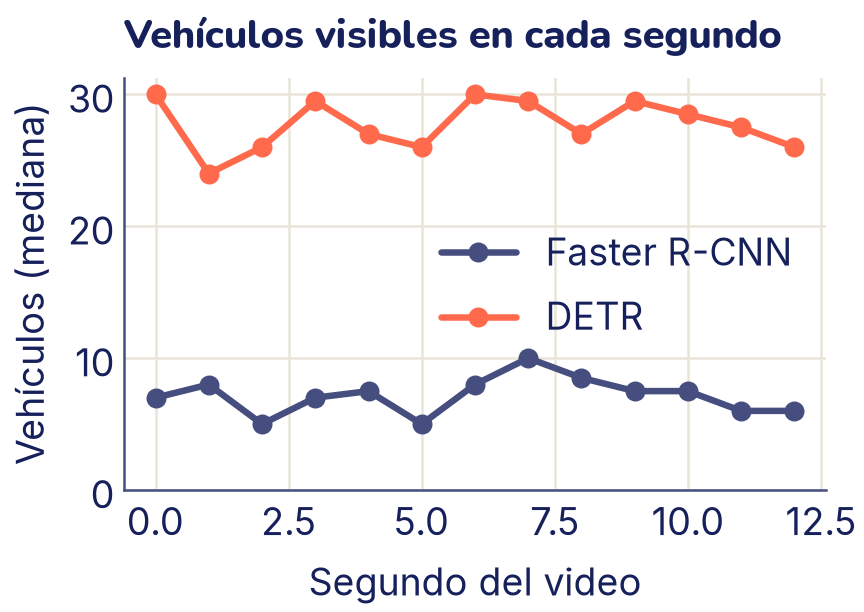

In [ ]:
plt.plot(segundos, con_frcnn, marker="o", color="C2",
         label="Faster R-CNN")
plt.plot(segundos, con_detr, marker="o", color="C1", label="DETR")
plt.xlabel("Segundo del video")
plt.ylabel("Vehículos (mediana)")
plt.ylim(0, None)
plt.legend()
plt.title("Vehículos visibles en cada segundo")
plt.show()

**4. ¿Quién tiene razón?** Elige un cuadro, cuenta los vehículos a mano y compara con los dos detectores. Dibuja las cajas de cada uno sobre ese cuadro (con `dibujar_cajas`) y mira cuáles se pierden.

**5. Para ir más lejos.** Escribe un seguimiento simple: entre dos cuadros analizados seguidos, empareja cada caja con la caja del cuadro anterior con la que tenga mayor IoU (si pasa de 0,3) y dale el mismo número; las que no se emparejan son objetos nuevos. Con eso puedes contar cuántos vehículos **distintos** aparecieron. Para que funcione, analiza cuadros más seguidos (`cada=3`): si los autos se mueven mucho entre dos cuadros, sus cajas ya no se cruzan.

<details>
<summary>Qué deberías ver</summary>

Con el video de la autopista, Faster R-CNN ve entre 5 y 10 vehículos a la vez en cada segundo del video y DETR entre 24 y 30: los dos siguen el mismo tráfico, pero DETR ve unas cuatro veces más. Si miras el cuadro de la teoría, hay varias decenas de autos a la vista, la mayoría chicos y lejanos: Faster R-CNN a 320 píxeles se pierde casi todos. DETR tarda varias veces más por cuadro (recuerda los tiempos de la teoría), pero para contar es mucho mejor.

Con tu video los números serán otros. Si la calle está cerca y los autos se ven grandes, los dos detectores pueden coincidir bastante; si está lejos, pasará lo mismo que aquí. El conteo por segundo sigue sin ser «vehículos que pasaron»: para eso necesitas el seguimiento del paso 5.

</details>

## Errores comunes

- **Mezclar formatos de caja.** xyxy, xywh y cxcywh (a veces normalizadas entre 0 y 1) son cuatro números en todos los casos; el código no falla, pero las cajas quedan mal. Dibújalas sobre la imagen antes de calcular nada.
- **Olvidar que OpenCV da BGR.** Si pasas un cuadro de `cv2` sin `cv2.cvtColor(cuadro, cv2.COLOR_BGR2RGB)`, el modelo ve los autos rojos azules y detecta peor.
- **Olvidar `modelo.eval()`.** Los detectores de `torchvision` en modo entrenamiento esperan las cajas correctas como entrada y dan un error; en la U-Net, BatchNorm se comporta distinto.
- **Elegir un umbral de IoU de NMS sin mirar.** Muy bajo, borra objetos pegados (autos en fila, personas en grupo); muy alto, deja cajas repetidas que se cuentan dos veces.
- **Aplicar NMS entre clases distintas** cuando los objetos se superponen de verdad (una persona sobre su bicicleta). La NMS se aplica por clase.
- **Medir la segmentación con la exactitud por píxel.** Cuando el fondo es la mayoría, un modelo que no ve nada saca una exactitud alta. Mide IoU o Dice por clase.
- **Aumentar la imagen y no la etiqueta.** Si volteas o recortas la imagen, la caja y la máscara tienen que cambiar igual. Usa `torchvision.transforms.v2` con `tv_tensors`.
- **Contar por cuadro y llamarlo «vehículos que pasaron».** El mismo auto aparece en muchos cuadros; para contar objetos distintos hace falta seguimiento.
- **Creer que el detector ve lo que tú ves.** Los modelos a 320 píxeles pierden los objetos chicos y se equivocan de clase (el peatón «bicicleta»). Revisa siempre algunas detecciones a ojo.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Explicar las cajas delimitadoras y sus formatos, y calcular el IoU (ejercicios 1 y 2).
- Explicar y programar la supresión de no máximos (ejercicios 3 y 4).
- Usar detectores preentrenados de una etapa (SSD, como YOLO), de dos etapas (Faster R-CNN) y basados en transformers (DETR) en fotos y en cuadros de video, y comparar su velocidad y su calidad (ejercicio 5 y pasos 2 a 4 del mini-proyecto).
- Explicar la U-Net: codificador, decodificador y conexiones de salto (ejercicio 8).
- Entrenar una U-Net pequeña y medirla con IoU y Dice, entendiendo por qué la exactitud por píxel engaña (ejercicios 6 y 7).
- Procesar un video como una secuencia de cuadros (pasos 2 y 3 del mini-proyecto).